
<table>
    <tr>
        <td><img src='https://coastalrisk.live/wp-content/uploads/2018/05/cera_50x50.png' alt='Image' width='50' height=50'></td>
        <td><h1 align="left"><font color='green'>Visualizing a Single NHC Track with Matplotlib </font></h1></td>
    </tr>
</table>


In [24]:
# Copyright (C): Carola Kaiser 2006-2026, Louisiana State University.
# This script is part of the Coastal Emergency Risks Assessment (CERA), a real-time visualization system for storm surge guidance.
# See https://cera.coastalrisk.live. This CERA script is Open Source software; distributed under the MIT License.

# Authors: Carola Kaiser, Efstratios Nikidis

# Part 1: Introduction

## 1.1 - Overview
This notebook renders one ATCF best-track `.dat` file into a publication-style map. It draws the track colored by 1-minute maximum wind, with start/end markers and an intensity legend.

The example input `bal142024.dat` and the output `example_1_plot.png` live directly in this tutorial folder.

**Pipeline:**

```
bal142024.dat  ->  parse advisories  ->  render map  ->  example_1_plot.png
```

## 1.2 - Tutorial example ATCF file
The notebook uses `bal142024.dat`, the Milton (2024) ATCF best-track file, placed directly in this folder. ATCF best-track files are provided by NHC (HURDAT2-derived).

## 1.3 - Importing the Python libraries
`INTENSITY_STYLES` holds the Saffir--Simpson bands (label, wind range in knots, color) used to color the track. The helper functions parse ATCF records and prepare the map styling.

In [25]:
import csv
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import warnings
import cartopy.io
warnings.filterwarnings('ignore', category=cartopy.io.DownloadWarning)

# ATCF timestamp format (YYYYMMDDHH).
ATCF_DATETIME_FORMAT = "%Y%m%d%H"

# Saffir--Simpson intensity: (label, lower kt, upper kt, color).
INTENSITY_STYLES = (
    ("Tropical Depression", 0, 33, "#6b7280"),
    ("Tropical Storm", 34, 63, "#2b8cbe"),
    ("Category 1", 64, 82, "#e6ab02"),
    ("Category 2", 83, 95, "#e67e22"),
    ("Category 3", 96, 112, "#d95f0e"),
    ("Category 4", 113, 136, "#c62828"),
    ("Category 5", 137, float("inf"), "#7b3294"),
)


def parse_coordinate(value: str) -> float:
    """Convert an ATCF tenths-of-a-degree coordinate such as 286N or 969W."""
    match = re.fullmatch(r"(\d+)([NSEW])", value.strip().upper())
    if not match:
        raise ValueError(f"Invalid ATCF coordinate: {value!r}")
    magnitude = int(match.group(1)) / 10.0
    return -magnitude if match.group(2) in {"S", "W"} else magnitude


def load_atcf_track(dat_path: Path) -> pd.DataFrame:
    """Load the core fields from an ATCF best-track file."""
    parsed_rows = []
    with dat_path.open(newline="", encoding="utf-8") as handle:
         for line_number, fields in enumerate(csv.reader(handle), start=1):
            fields = [field.strip() for field in fields]
            if not fields or all(not field for field in fields):
                continue
            if len(fields) < 11:
                raise ValueError(
                    f"{dat_path}:{line_number} has {len(fields)} fields; expected at least 11"
                )
            try:
                parsed_rows.append(
                    {
                        "basin": fields[0],
                        "storm_number": fields[1],
                        "time": pd.to_datetime(fields[2], format=ATCF_DATETIME_FORMAT, errors="raise"),
                        "technique": fields[4],
                        "latitude": parse_coordinate(fields[6]),
                        "longitude": parse_coordinate(fields[7]),
                        "vmax_kt": pd.to_numeric(fields[8], errors="coerce"),
                        "pressure_hpa": pd.to_numeric(fields[9], errors="coerce"),
                        "status": fields[10],
                    }
                )
            except ValueError as exc:
                raise ValueError(f"{dat_path}:{line_number}: {exc}") from exc
 
    track = pd.DataFrame(parsed_rows)
    if track.empty:
        raise ValueError(f"No track records found in {dat_path}")

    # ATCF files may repeat a timestamp for different wind-radii records; those
    # share a center position, so one point per advisory is enough here.
    track = (
        track.sort_values("time")
        .drop_duplicates(subset=["time"], keep="first")
        .reset_index(drop=True)
    )
    return track


def padded_extent(track: pd.DataFrame) -> list:
    lon_min = float(track["longitude"].min())
    lon_max = float(track["longitude"].max())
    lat_min = float(track["latitude"].min())
    lat_max = float(track["latitude"].max())
    lon_pad = max((lon_max - lon_min) * 0.12, 2.5)
    lat_pad = max((lat_max - lat_min) * 0.12, 2.0)
    return [lon_min - lon_pad, lon_max + lon_pad, lat_min - lat_pad, lat_max + lat_pad]


def intensity_label(vmax_kt) -> str:
    if pd.isna(vmax_kt):
        return "Unknown"
    for label, lower, upper, _color in INTENSITY_STYLES:
        if lower <= vmax_kt <= upper:
            return label
    return "Unknown"


def intensity_color(label: str) -> str:
    for candidate, _lower, _upper, color in INTENSITY_STYLES:
        if label == candidate:
            return color
    return "#9ca3af"


def add_base_features(ax) -> None:
    """Apply the same Natural Earth visual language as the station-map notebook."""
    ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#D8DBDE", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#FFFFFF", zorder=0)
    ax.add_feature(cfeature.LAKES.with_scale("10m"), facecolor="#D8DBDE",
                   edgecolor="#A8A8A8", linewidth=0.25, zorder=1)
    ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#A8A8A8",
                   linewidth=0.22, alpha=0.75, zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), edgecolor="#A8A8A8",
                   linewidth=0.45, alpha=0.65, zorder=2)
    #ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#CFCFCF",
    #               linewidth=0.30, alpha=0.55, zorder=2)
    #ax.add_feature(cfeature.STATES.with_scale("10m"), edgecolor="#CFCFCF",
    #               linewidth=0.30, alpha=0.55, zorder=2)

# Part 2: Track Visualization

## 2.1 - Input and output
The notebook reads `bal142024.dat` and writes `example_1_plot.png`, both directly in this tutorial folder.

Edit the input cell below:

- **`STORM_NAME` / `YEAR`** --- used for the map title.
- **`DPI`** --- resolution of the saved image.

ATCF files store the basin code and storm **number**, not the name, so set `STORM_NAME` and `YEAR` explicitly.

In [26]:
# ----------------------------------------------------------------------
# INPUT
# ----------------------------------------------------------------------
STORM_NAME = "Milton"   # optional display name ("" -> generic title)
YEAR       = "2024"      # optional year ("" -> omitted from the title)

DPI = 300                # raster output DPI

## 2.2 - Checking the input file
The notebook reads `bal142024.dat` from this folder. If it is missing, place it next to the notebook before rendering.

In [27]:
if not Path("bal142024.dat").exists():
    raise FileNotFoundError(
        "bal142024.dat not found. Place the ATCF best-track file next to this notebook."
    )

print("Using: bal142024.dat")

Using: bal142024.dat


## 2.3 - Rendering and saving the map
Parses the advisories, colors each point by intensity, draws the connecting track line, and marks the start (green circle) and end (black X). The `Intensity (1-min wind)` legend lists only the bands that actually occur in the file. The result is saved as `example_1_plot.png`.

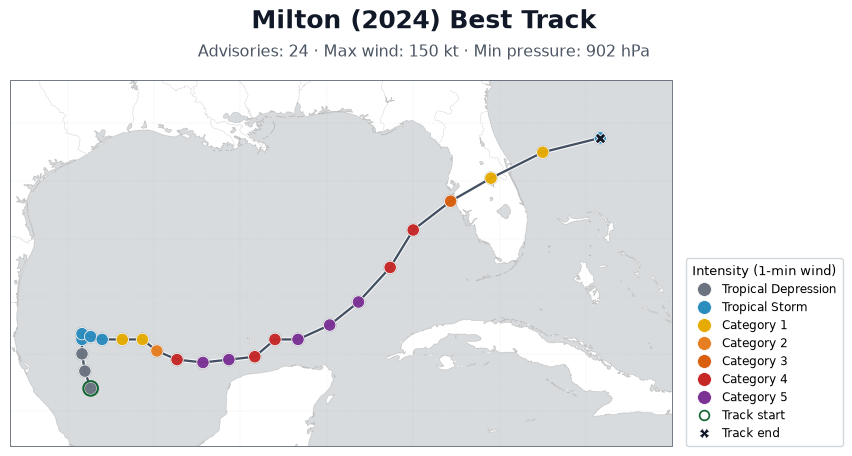

Saved: example_1_plot.png


In [28]:
"""Render a single ATCF best-track file into a publication-style map."""
track = load_atcf_track(Path("bal142024.dat"))
track["intensity"] = track["vmax_kt"].map(intensity_label)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.titlesize": 14,
    "legend.fontsize": 8,
})

projection = ccrs.PlateCarree()
fig = plt.figure(figsize=(9.2, 6.8), constrained_layout=False)
ax = fig.add_axes([0.05, 0.085, 0.72, 0.78], projection=projection)
ax.set_extent(padded_extent(track), crs=projection)
add_base_features(ax)

gridlines = ax.gridlines(draw_labels=False, linewidth=0.28, color="#9aa5ad",
    alpha=0.42, linestyle=(0, (2, 3)))

for spine in ax.spines.values():
    spine.set_linewidth(0.55)
    spine.set_edgecolor("#4b5563")
        
# track
line = ax.plot(
    track["longitude"], track["latitude"], transform=projection,
    color="#334155", linewidth=1.65, alpha=0.92, zorder=5,
)[0]
line.set_path_effects([pe.Stroke(linewidth=3.2, foreground="white", alpha=0.8), pe.Normal()])

present_labels = []
for label, _lower, _upper, color in INTENSITY_STYLES:
    group = track[track["intensity"] == label]
    if group.empty:
        continue
    present_labels.append(label)
    ax.scatter(
        group["longitude"], group["latitude"], transform=projection, s=80, marker="o",
        facecolor=color, edgecolor="white", linewidth=0.6, alpha=0.96, zorder=6,
        path_effects=[pe.withStroke(linewidth=1.1, foreground="#263238", alpha=0.28)],
    )

start = track.iloc[0]
end = track.iloc[-1]
ax.scatter([start["longitude"]], [start["latitude"]], transform=projection, s=110,
    marker="o", facecolor="none", edgecolor="#166534", linewidth=1.5, zorder=7)
ax.scatter([end["longitude"]], [end["latitude"]], transform=projection, s=58,
    marker="X", facecolor="#111827", edgecolor="white", linewidth=0.55, zorder=7)

max_wind = track["vmax_kt"].max()
min_pressure = track.loc[track["pressure_hpa"] > 0, "pressure_hpa"].min()
max_wind_text = "n/a" if pd.isna(max_wind) else f"{int(max_wind)} kt"
pressure_text = "n/a" if pd.isna(min_pressure) else f"{int(min_pressure)} hPa"

title = f"{STORM_NAME.title()} ({YEAR}) Best Track" if STORM_NAME else "ATC Best Track"
fig.text(0.50, 0.830, title, ha="center", va="center", fontsize=18,
    fontweight="bold", color="#111827")
fig.text(0.50, 0.785,
    f"Advisories: {len(track)} \u00b7 Max wind: {max_wind_text} \u00b7 Min pressure: {pressure_text}",
    ha="center", va="center", fontsize=11.5, color="#4b5563")

intensity_handles = [
    mlines.Line2D([], [], marker="o", linestyle="None", markersize=10,
        markerfacecolor=intensity_color(label), markeredgecolor="white",
        markeredgewidth=0.55, label=label)
    for label in present_labels
]
endpoint_handles = [
    mlines.Line2D([], [], marker="o", linestyle="None", markersize=7,
        markerfacecolor="none", markeredgecolor="#166534",
        markeredgewidth=1.25, label="Track start"),
    mlines.Line2D([], [], marker="X", linestyle="None", markersize=6.5,
        markerfacecolor="#111827", markeredgecolor="white",
        markeredgewidth=0.5, label="Track end"),
]
ax.legend(
    handles=[*intensity_handles, *endpoint_handles], title="Intensity (1-min wind)",
    loc="lower left", bbox_to_anchor=(1.02, 0.0), borderaxespad=0.0,
    frameon=True, framealpha=0.95,
    facecolor="white", edgecolor="#d0d5da", borderpad=0.5, labelspacing=0.42,
    handletextpad=0.55, fontsize=8.6, title_fontsize=9.0,
)

fig.savefig("example_1_plot.png", dpi=DPI, facecolor="white")
plt.show()
plt.close(fig)
print("Saved: example_1_plot.png")

# Part 3: Output

## 3.1 - Output file
The map is written to `example_1_plot.png` in this folder. To plot a different storm, replace
`bal142024.dat` and update `STORM_NAME` / `YEAR`, then re-run.